# 01. Загрузка данных, парсинг и разведочный анализ (EDA)

**Датасет:** [`ViliamVolosV/russian_classic_literature`](https://huggingface.co/datasets/ViliamVolosV/russian_classic_literature)
(`train_dataset.json`, `validation_dataset.json`, `test_dataset.json`, формат JSON Lines).

Каждая запись — диалог `messages` из трёх сообщений (`system`, `user`, `assistant`):
* **класс `y`** — имя автора из сообщения `user`;
* **текст `X`** — литературный фрагмент из сообщения `assistant`.

In [1]:
import sys
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.preprocessing import (  # noqa: E402
    AUTHOR_RE_FALLBACK,
    AUTHOR_RE_PRIMARY,
    chunk_text,
    clean_text,
    iter_jsonl,
    parse_record,
)

RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
for p in (RAW, PROCESSED, FIG):
    p.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)

## 1. Загрузка с Hugging Face Hub
Файлы скачиваются один раз в `data/raw/` (директория `data/` в `.gitignore`).

In [2]:
HF_URL = "https://huggingface.co/datasets/ViliamVolosV/russian_classic_literature/resolve/main/{}"
SPLITS = {"train": "train_dataset.json", "validation": "validation_dataset.json", "test": "test_dataset.json"}

for fname in SPLITS.values():
    target = RAW / fname
    if not target.exists():
        print("download", fname)
        urllib.request.urlretrieve(HF_URL.format(fname), target)
    print(f"{fname:<25} {target.stat().st_size / 2**20:8.1f} MB")

train_dataset.json           192.6 MB
validation_dataset.json       17.0 MB
test_dataset.json             17.0 MB


## 2. Парсинг диалоговой структуры `messages`

Регулярное выражение из ТЗ `r"стиле автора ([^\"]+)"` покрывает только один из
четырёх шаблонов запросов, встречающихся в датасете. Проверим покрытие:

In [3]:
records = {split: list(iter_jsonl(RAW / fname)) for split, fname in SPLITS.items()}

templates = Counter()
coverage = Counter()
for rec in records["train"]:
    user = next(m["content"] for m in rec["messages"] if m["role"] == "user")
    templates[" ".join(user.split()[:3])] += 1
    coverage["primary"] += bool(AUTHOR_RE_PRIMARY.search(user))
    coverage["primary_or_fallback"] += bool(AUTHOR_RE_PRIMARY.search(user) or AUTHOR_RE_FALLBACK.search(user))

print("Шаблоны user-сообщений (train):")
for t, c in templates.most_common():
    print(f"  {c:5d}  «{t} …»")
n = len(records["train"])
print(f"\nПокрытие regex из ТЗ:            {coverage['primary']:5d} / {n} ({coverage['primary'] / n:.1%})")
print(f"Покрытие regex из ТЗ + fallback: {coverage['primary_or_fallback']:5d} / {n} ({coverage['primary_or_fallback'] / n:.1%})")

Шаблоны user-сообщений (train):
   3258  «Придумай отрывок из …»
   1636  «Напиши текс в …»
   1598  «Придумай текс похожий …»
   1526  «Напиши текс похожий …»

Покрытие regex из ТЗ:             1636 / 8018 (20.4%)
Покрытие regex из ТЗ + fallback:  8018 / 8018 (100.0%)


Только ~20 % записей содержат фразу «в стиле автора». Чтобы **не потерять ни одного
автора и ни одной записи**, используется основное выражение из ТЗ и резервное
`r"автора\s+([^\"]+?)\s*$"` (во всех шаблонах имя автора стоит в конце строки после слова «автора»).

In [4]:
rows = []
for split, recs in records.items():
    for i, rec in enumerate(recs):
        author, text = parse_record(rec)
        rows.append({"split": split, "doc_id": f"{split}_{i:05d}", "author": author, "raw_text": text})
df = pd.DataFrame(rows)
print(df.groupby("split").size())
print("Записей без автора:", df["author"].isna().sum())
df.head()

split
test           708
train         8018
validation     708
dtype: int64
Записей без автора: 0


,split,doc_id,author,raw_text
0,train,train_00000,Платонов С,"Никон, подавленный отношением царя к нему, и раньше искал мира, посылая к царю письма и прося его перемениться к нем..."
1,train,train_00001,Достоевский Ф,"- За мной? А мои странствия как раз кончились и как раз сегодня: ты опоздал, мой милый. Сегодня - финал последнего а..."
2,train,train_00002,Гончаров И,"Кто начинает только завтракать, кто пьет чай; а этот, ожидая, когда удастся, за толпой, подойти к столу и взять чего..."
3,train,train_00003,Толстой Л,"""Удивительно добрый человек"", - думал Левин.\n - Ну, а ты, Егор, когда женился, ты любил свою жену?\n - Как же..."
4,train,train_00004,Горький Максим,"- Мало нас, вот о чем! Необходимо работать энергичнее... и необходимо убедить Павла и Андрея бежать, они оба слишком..."


## 3. Очистка данных
* исправление «битых» экранирований (`\\n`, `\\"` …);
* нормализация переносов строк `\r\n` → `\n`;
* удаление управляющих символов, дублирующихся пробелов и пустых строк;
* фильтрация пустых текстов и артефактов парсинга (слишком короткие фрагменты).

In [5]:
sample = df.loc[0, "raw_text"][:400]
print("ДО:\n", repr(sample))
print("\nПОСЛЕ:\n", repr(clean_text(sample)))

ДО:
 'Никон, подавленный отношением царя к нему, и раньше искал мира, посылая к царю письма и прося его перемениться к нему "Господа ради";\r\nтеперь же он решил тайком приехать в Москву и приехал ночью (на Рождество 1662 г.\r\n), чтобы примириться с государем и предотвратить собор, но той же ночью уехал обратно, извещенный, вероятно, своими московскими друзьями, что его попытка будет напрасной.\r\nВидя, что '

ПОСЛЕ:
 'Никон, подавленный отношением царя к нему, и раньше искал мира, посылая к царю письма и прося его перемениться к нему "Господа ради";\nтеперь же он решил тайком приехать в Москву и приехал ночью (на Рождество 1662 г.\n), чтобы примириться с государем и предотвратить собор, но той же ночью уехал обратно, извещенный, вероятно, своими московскими друзьями, что его попытка будет напрасной.\nВидя, что'


In [6]:
df["text"] = df["raw_text"].map(clean_text)
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len().fillna(0).astype(int)

MIN_CHARS = 200
bad = df[(df["author"].isna()) | (df["n_chars"] < MIN_CHARS)]
print(f"Отфильтровано (пустые / < {MIN_CHARS} символов / без автора): {len(bad)}")
print(bad[["split", "doc_id", "author", "n_chars"]])
dup = df.duplicated("text", keep="first")
print("Дубликатов текстов:", dup.sum())
df = df[(df["author"].notna()) & (df["n_chars"] >= MIN_CHARS) & ~dup].drop(columns="raw_text").reset_index(drop=True)
print(df.groupby("split").size())

Отфильтровано (пустые / < 200 символов / без автора): 1
      split       doc_id     author  n_chars
6338  train  train_06338  Андреев Л        0
Дубликатов текстов: 0


split
test           708
train         8017
validation     708
dtype: int64


Проверим пересечение текстов между выборками (утечка данных):

In [7]:
sets = {s: set(g["text"]) for s, g in df.groupby("split")}
print("train ∩ validation:", len(sets["train"] & sets["validation"]))
print("train ∩ test:      ", len(sets["train"] & sets["test"]))
print("validation ∩ test: ", len(sets["validation"] & sets["test"]))

train ∩ validation: 0
train ∩ test:       0
validation ∩ test:  0


## 4. EDA: распределение классов

In [8]:
counts = df.pivot_table(index="author", columns="split", values="doc_id", aggfunc="count", fill_value=0)
counts = counts[["train", "validation", "test"]].sort_values("train", ascending=False)
print("Всего авторов:", len(counts))
print("Авторов в train:", (counts["train"] > 0).sum())
print("Авторов в test, отсутствующих в train:", ((counts["test"] > 0) & (counts["train"] == 0)).sum())
counts

Всего авторов: 64
Авторов в train: 64
Авторов в test, отсутствующих в train: 0


split,train,validation,test
author,,,
Достоевский Ф,714,69,60
Лесков Н,649,58,63
Толстой Л,562,44,51
Чехов А,433,39,37
Карамзин Н,370,30,34
Мамин-Сибиряк Д,302,27,28
Гончаров И,300,19,23
Салтыков-Щедрин М,293,25,31
Тургенев И,285,25,22


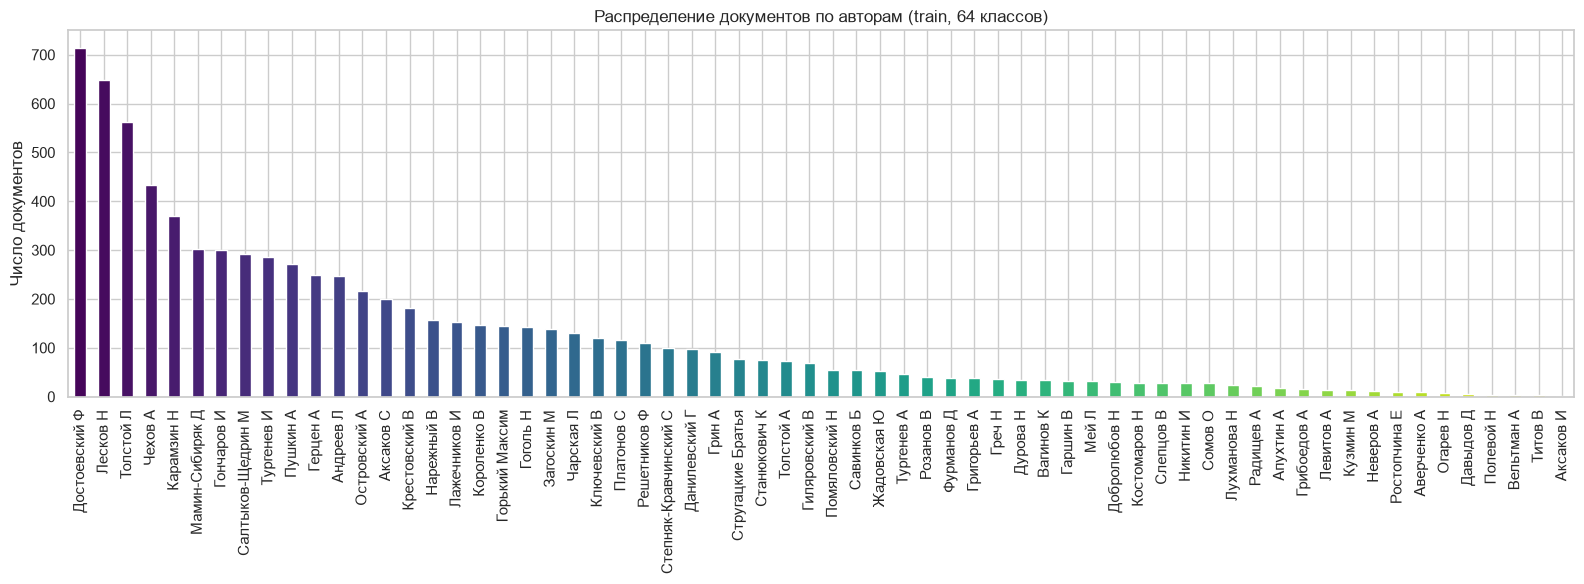

In [9]:
fig, ax = plt.subplots(figsize=(16, 6))
counts["train"].plot.bar(ax=ax, color=sns.color_palette("viridis", len(counts)))
ax.set_title(f"Распределение документов по авторам (train, {len(counts)} классов)")
ax.set_ylabel("Число документов")
ax.set_xlabel("")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(FIG / "class_distribution.png", dpi=120)
plt.show()

In [10]:
tr = counts["train"]
print(f"Максимум: {tr.max()} ({tr.idxmax()}), минимум: {tr.min()} ({tr.idxmin()})")
print(f"Коэффициент дисбаланса max/min: {tr.max() / tr.min():.0f}")
print(f"Топ-10 авторов покрывают {tr.head(10).sum() / tr.sum():.1%} train")
print(f"Авторов с < 20 документами: {(tr < 20).sum()}")

Максимум: 714 (Достоевский Ф), минимум: 1 (Аксаков И)
Коэффициент дисбаланса max/min: 714
Топ-10 авторов покрывают 52.1% train
Авторов с < 20 документами: 13


## 5. EDA: длины текстов

In [11]:
def length_stats(s: pd.Series) -> pd.Series:
    return pd.Series({"mean": s.mean(), "median": s.median(), "p95": s.quantile(0.95), "min": s.min(), "max": s.max()})


stats = pd.concat(
    {
        (split, col): length_stats(g[col])
        for split, g in df.groupby("split")
        for col in ("n_chars", "n_words")
    },
    axis=1,
).T.round(1)
stats

mean   median      p95     min      max
test       n_chars  13515.1  13757.0  13850.0  2360.0  16666.0
           n_words   2151.5   2181.0   2370.6   360.0   2999.0
train      n_chars  13499.3  13756.0  13857.0   727.0  17321.0
           n_words   2153.3   2178.0   2380.0   118.0   3537.0
validation n_chars  13487.5  13754.5  13854.6  3842.0  16290.0
           n_words   2153.4   2177.0   2371.6   624.0   3187.0

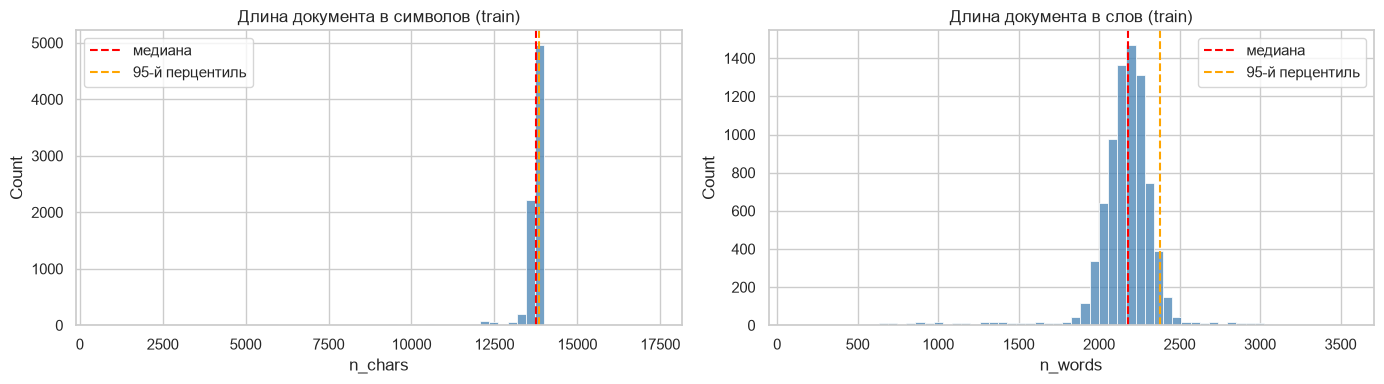

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, title in zip(axes, ("n_chars", "n_words"), ("символов", "слов")):
    sns.histplot(df[df.split == "train"][col], bins=60, ax=ax, color="steelblue")
    ax.axvline(df[col].median(), color="red", ls="--", label="медиана")
    ax.axvline(df[col].quantile(0.95), color="orange", ls="--", label="95-й перцентиль")
    ax.set_title(f"Длина документа в {title} (train)")
    ax.legend()
plt.tight_layout()
plt.savefig(FIG / "length_distribution.png", dpi=120)
plt.show()

**Наблюдения:**
* Документы почти одинаковой длины (~14 000 символов, ~2 200 слов) — это нарезка книг фиксированным окном.
* Пользователь же будет присылать на `/ask` короткие фрагменты. Поэтому обучение ведётся на
  **фрагментах ~1000 символов** (≈150 слов, ≈220 токенов ruBERT — помещается в окно 256 токенов),
  а предсказание для длинного текста получается усреднением вероятностей по фрагментам.
* Нарезка также многократно увеличивает обучающую выборку, особенно для редких авторов.

## 6. Нарезка на фрагменты

In [13]:
CHUNK_CHARS = 1000
chunk_rows = []
for row in df.itertuples(index=False):
    for j, chunk in enumerate(chunk_text(row.text, chunk_chars=CHUNK_CHARS)):
        chunk_rows.append({"split": row.split, "doc_id": row.doc_id, "chunk_id": j, "author": row.author, "text": chunk})
chunks = pd.DataFrame(chunk_rows)
chunks["n_chars"] = chunks["text"].str.len()
print(chunks.groupby("split").size())
print(chunks.groupby("split")["n_chars"].describe().round(0))

split
test            9748
train         110285
validation      9735
dtype: int64
               count   mean   std    min     25%     50%     75%     max
split                                                                   
test          9748.0  981.0  84.0  218.0  1000.0  1002.0  1004.0  1198.0
train       110285.0  980.0  86.0  200.0  1000.0  1002.0  1004.0  1232.0
validation    9735.0  980.0  90.0  215.0  1000.0  1002.0  1004.0  1175.0


In [14]:
chunk_counts = chunks[chunks.split == "train"]["author"].value_counts()
print("Фрагментов на автора (train): min =", chunk_counts.min(), "| median =", int(chunk_counts.median()), "| max =", chunk_counts.max())

Фрагментов на автора (train): min = 7 | median = 854 | max = 9907


## 7. Экспорт в `data/processed/`

In [15]:
for split in ("train", "validation", "test"):
    name = "parsed_validation" if split == "validation" else f"parsed_{split}"
    df[df.split == split].reset_index(drop=True).to_parquet(PROCESSED / f"{name}.parquet", index=False)
    chunks[chunks.split == split].reset_index(drop=True).to_parquet(PROCESSED / f"chunks_{split}.parquet", index=False)

for f in sorted(PROCESSED.glob("*.parquet")):
    print(f"{f.name:<30} {f.stat().st_size / 2**20:7.1f} MB")

chunks_test.parquet                8.5 MB
chunks_train.parquet              95.7 MB
chunks_validation.parquet          8.4 MB
parsed_test.parquet                8.5 MB
parsed_train.parquet              95.5 MB
parsed_validation.parquet          8.4 MB
